## 1. Cargar y comprobar los datos
Se valida que los archivos estén completos, que sus identificadores sean únicos y que la plantilla coincida con test. Los valores de ejemplo de `sample_submission` no son etiquetas reales.

# Licitaciones: segunda versión y comparación

**Resultado de la ejecución incluida:** las pruebas no confirmaron una mejora consistente. El nuevo CSV es experimental; no se recomienda reemplazar el envío anterior suponiendo que este será superior. La conclusión detalla los resultados favorables y desfavorables.

**Motivación.** La captura de Kaggle muestra **0,38168**, mientras que la evaluación local anterior obtuvo F1 **0,39733**. Son datos de períodos distintos; el segundo valor no era una promesa de resultado en Kaggle. La diferencia es aproximadamente 0,01565 en F1. La captura no incluye las predicciones ni los parámetros del archivo subido; asumimos que corresponde a la versión anterior.

El objetivo es construir un **nuevo candidato respaldado por comparaciones locales**, conservando lo que aportó señal. No ajustamos parámetros para intentar reproducir el único número público de Kaggle.

**Qué conservamos:** texto de título + descripción + categoría; comprador y categorías codificadas; TF-IDF con 60.000 términos, `min_df=3` y palabras/pares de palabras; transformaciones logarítmicas y tratamiento de faltantes.

**Qué revisamos:** dependencia del mes, pesos de clases, combinaciones comprador–categoría, conteos de publicaciones anteriores, regularización y estabilidad del umbral. También comparamos la mezcla anterior con alternativas más simples.

**Cambio de procedimiento:** el modelo con el que se ajusta el umbral se mantiene fijo para predecir el bloque siguiente y para generar el submission. No se reentrena después del ajuste final.

### Uso en Colab
Sube los tres CSV completos, con o sin `(1)` en sus nombres, y ejecuta las celdas en orden. La búsqueda usa CPU y puede tardar decenas de minutos. El notebook contiene las salidas de la ejecución incluida y termina generando `submission_licitaciones_v2.csv`.

`1` significa desierta y `0`, no desierta según la etiqueta; no equivale necesariamente a que el contrato se haya ejecutado. Se optimiza F1 de la clase 1, conforme a la métrica que estamos comparando.

In [ ]:
import time, json, gc
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
    average_precision_score, roc_auc_score, accuracy_score,
    precision_recall_curve, confusion_matrix)
from threadpoolctl import threadpool_limits

SEMILLA = 2026
TARGET = 'y_desierta'
N_HILOS = 4


import sklearn
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Markdown
except ImportError:
    display=print
    Markdown=str
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',90)
print({'sklearn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__})

{'sklearn': '1.8.0', 'pandas': '2.2.3', 'numpy': '2.3.5'}


In [ ]:
RUTA_DATOS=Path('.')
def localizar(nombre):
    opciones=[RUTA_DATOS/f'{nombre}.csv',RUTA_DATOS/f'{nombre}(1).csv']
    for p in opciones:
        if p.exists():return p
    raise FileNotFoundError(f'Sube {nombre}.csv antes de ejecutar.')
tipos={'id':str,'comprador_id':str,'comprador_rut':str}
datos=pd.read_csv(localizar('train'),dtype=tipos)
test=pd.read_csv(localizar('test'),dtype=tipos)
plantilla=pd.read_csv(localizar('sample_submission'),dtype={'id':str})
assert len(datos)==152553 and len(test)==len(plantilla)==21829, 'Revisar archivos incompletos o distintos.'
assert set(datos[TARGET].unique())=={0,1} and datos[TARGET].notna().all()
assert TARGET not in test and set(datos.columns)-{TARGET}==set(test.columns)
for d in [datos,test,plantilla]:assert d.id.notna().all() and d.id.is_unique
assert set(datos.id).isdisjoint(set(test.id)) and set(test.id)==set(plantilla.id)
assert plantilla.columns.tolist()==['id',TARGET]
for d in [datos,test]:
    d['pub_fecha']=pd.to_datetime(d.pub_fecha,utc=True,errors='coerce')
    assert d.pub_fecha.notna().all()
assert datos.pub_fecha.max()<test.pub_fecha.min()
display(pd.DataFrame({'filas':[len(datos),len(test)],
    'desde':[datos.pub_fecha.min(),test.pub_fecha.min()],
    'hasta':[datos.pub_fecha.max(),test.pub_fecha.max()]},index=['train','test']))
display(pd.DataFrame({'monto_ausente':[datos.pub_monto_estimado.isna().mean(),test.pub_monto_estimado.isna().mean()]},index=['train','test']))
print('Compradores de test no vistos en train:',round(100*(~test.comprador_id.isin(datos.comprador_id)).mean(),2),'%')

,filas,desde,hasta
train,152553,2024-01-04 17:06:15+00:00,2024-12-31 22:29:20+00:00
test,21829,2025-01-01 20:17:01+00:00,2025-03-31 23:45:57+00:00


,monto_ausente
train,0.440935
test,0.531357


Compradores de test no vistos en train: 1.18 %


**Interpretación.** Test pertenece a otro año y la proporción de montos ausentes puede cambiar. Esto señala una diferencia entre conjuntos, pero no demuestra la causa de la caída de F1. Las etiquetas de 2025 siguen siendo desconocidas; no se puede elegir un umbral óptimo para test usando sus respuestas.

## 2. Variables conservadas y nuevas hipótesis
Las variables base se construyen con información de la publicación. El ID de la licitación se excluye del modelo.

| Cambio | Hipótesis que se comprueba |
|---|---|
| Quitar seno/coseno del mes | Una sola temporada anual puede producir patrones poco estables al pasar de 2024 a 2025 |
| `class_weight=None` frente a `balanced` | El peso de clases no siempre mejora F1 cuando también se ajusta el umbral |
| Institución y comprador–categoría | Una institución puede tener varias unidades compradoras, y su experiencia puede variar por categoría |
| Conteos de publicaciones anteriores | La actividad previa puede complementar la identidad de comprador y categoría |
| C = 0,05 / 0,2 / 1 en la variante ampliada | Limitar el sobreajuste de las nuevas variables |

La institución se representa mediante el identificador `comprador_rut`, como categoría, nunca como cantidad. No se utiliza nombre ni dirección. Los conteos de historial **no contienen tasas de desiertas ni etiquetas**: solo cuentan publicaciones de entrenamiento estrictamente anteriores a la fila. Las publicaciones del bloque de ajuste, evaluación o test no actualizan esa referencia.

In [ ]:
NUM_BASICAS = ['log_items', 'log_cantidad', 'log_categorias',
               'dias_postulacion', 'dias_consultas']
CAT_BASICAS = ['metodo', 'modalidad', 'moneda', 'region']
NUM_EXTRA = ['log_monto', 'monto_ausente', 'moneda_ausente', 'consultas',
             'log_largo_titulo', 'log_largo_descripcion',
             'mes_sin', 'mes_cos', 'dia_semana', 'hora_cierre', 'dia_cierre']
CAT_EXTRA = ['comprador_id', 'categoria_id', 'categoria_1', 'categoria_2']

def crear_variables(df):
    """Solo usa información de la fila; nunca lee y_desierta ni aprende estadísticas."""
    X = pd.DataFrame(index=df.index)
    for origen, destino in [('pub_n_items', 'log_items'),
                            ('pub_cantidad_total', 'log_cantidad'),
                            ('pub_n_categorias', 'log_categorias'),
                            ('pub_monto_estimado', 'log_monto')]:
        valores = pd.to_numeric(df[origen], errors='coerce')
        X[destino] = np.log1p(valores.where(valores >= 0))
    X['dias_postulacion'] = pd.to_numeric(df['pub_dias_postulacion'], errors='coerce')
    X['dias_consultas'] = pd.to_numeric(df['pub_dias_consultas'], errors='coerce')
    X['monto_ausente'] = df['pub_monto_estimado'].isna().astype(int)
    X['moneda_ausente'] = df['pub_moneda'].isna().astype(int)
    X['consultas'] = df['pub_tiene_consultas'].astype(str).str.lower().isin(['true','1']).astype(int)
    titulo = df['pub_titulo'].fillna('').astype(str)
    descripcion = df['pub_descripcion'].fillna('').astype(str)
    categoria = df['pub_categoria'].fillna('').astype(str)
    X['log_largo_titulo'] = np.log1p(titulo.str.len())
    X['log_largo_descripcion'] = np.log1p(descripcion.str.len())
    fecha = pd.to_datetime(df['pub_fecha'], utc=True, errors='coerce')
    cierre = pd.to_datetime(df['pub_cierre'], utc=True, errors='coerce')
    X['mes_sin'] = np.sin(2*np.pi*fecha.dt.month/12)
    X['mes_cos'] = np.cos(2*np.pi*fecha.dt.month/12)
    X['dia_semana'] = fecha.dt.dayofweek
    X['hora_cierre'] = cierre.dt.hour
    X['dia_cierre'] = cierre.dt.dayofweek
    for origen, destino in [('pub_metodo','metodo'), ('pub_modalidad','modalidad'),
                            ('pub_moneda','moneda'), ('region','region'),
                            ('comprador_id','comprador_id')]:
        X[destino] = df[origen].fillna('SIN_DATO').astype(str)
    X['categoria_id'] = pd.to_numeric(df['pub_categoria_id'], errors='coerce').astype('Int64').astype(str)
    partes = categoria.str.split('/')
    X['categoria_1'] = partes.str[0].fillna('SIN_DATO').str.strip()
    X['categoria_2'] = partes.str[:2].str.join(' / ').fillna('SIN_DATO')
    X['texto'] = titulo + ' ' + descripcion
    X['texto_categoria'] = X['texto'] + ' ' + categoria
    X['titulo'] = titulo
    return X

class FrecuenciaCategoria(BaseEstimator, TransformerMixin):
    """Frecuencias sin etiquetas, aprendidas exclusivamente en fit."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.mapas_ = [X.iloc[:,j].value_counts(normalize=True) for j in range(X.shape[1])]
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        return np.column_stack([X.iloc[:,j].map(m).fillna(0).to_numpy()
                                for j,m in enumerate(self.mapas_)])

In [ ]:
def medir(y,p,umbral):
    pred = np.asarray(p)>=umbral
    return dict(f1=f1_score(y,pred,zero_division=0),
        precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0),
        ap=average_precision_score(y,p), roc_auc=roc_auc_score(y,p),
        accuracy=accuracy_score(y,pred), tasa_predicha=float(pred.mean()))

class VariablesTemporales(BaseEstimator, TransformerMixin):
    """Cuenta publicaciones anteriores, nunca desenlaces anteriores."""
    def __init__(self, historial=False):
        self.historial=historial
    def fit(self, X, y=None):
        self.referencias_={}
        if self.historial:
            base=crear_variables(X)
            base['comprador_categoria']=base['comprador_id']+'|'+base['categoria_id']
            fechas=pd.to_datetime(X.pub_fecha,utc=True).to_numpy(dtype='datetime64[ns]').astype('int64')
            for clave in ['comprador_id','categoria_id','comprador_categoria']:
                aux=pd.DataFrame({'clave':base[clave].to_numpy(),'fecha':fechas})
                self.referencias_[clave]={k:np.sort(g.fecha.to_numpy()) for k,g in aux.groupby('clave',sort=False)}
        return self
    def transform(self, X):
        F=crear_variables(X)
        F['comprador_categoria']=F['comprador_id']+'|'+F['categoria_id']
        F['institucion']=X['comprador_rut'].fillna('SIN_DATO').astype(str)
        if self.historial:
            fechas=pd.to_datetime(X.pub_fecha,utc=True).to_numpy(dtype='datetime64[ns]').astype('int64')
            for clave,mapa in self.referencias_.items():
                conteos=np.zeros(len(F),dtype=float)
                for k,pos in F.groupby(clave,sort=False).indices.items():
                    ref=mapa.get(k)
                    if ref is not None: conteos[pos]=np.searchsorted(ref,fechas[pos],side='left')
                F['hist_'+clave]=np.log1p(conteos)
        return F

def crear_modelo_v2(cfg):
    nums=NUM_BASICAS+NUM_EXTRA
    if not cfg.get('mes',True): nums=[c for c in nums if c not in ['mes_sin','mes_cos']]
    cats=CAT_BASICAS+CAT_EXTRA
    if cfg.get('cruces',False): cats=cats+['institucion','comprador_categoria']
    if cfg.get('historial',False): nums=nums+['hist_comprador_id','hist_categoria_id','hist_comprador_categoria']
    if cfg['familia']=='arboles':
        pre=ColumnTransformer([
            ('num','passthrough',nums),
            ('freq',FrecuenciaCategoria(),['comprador_id','categoria_id']),
            ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan,max_categories=200),cats)
        ],sparse_threshold=0)
        clf=HistGradientBoostingClassifier(learning_rate=.08,max_iter=300,max_leaf_nodes=31,
            min_samples_leaf=100,l2_regularization=10,early_stopping=False,
            categorical_features=[False]*(len(nums)+2)+[True]*len(cats),random_state=SEMILLA)
    else:
        pre=ColumnTransformer([
            ('num',Pipeline([('imputar',SimpleImputer(strategy='median',add_indicator=True)),
                             ('escalar',StandardScaler(with_mean=False))]),nums),
            ('cat',OneHotEncoder(handle_unknown='ignore',min_frequency=10),cats),
            ('tfidf',TfidfVectorizer(max_features=60000,min_df=3,ngram_range=(1,2),
                                    sublinear_tf=True),'texto_categoria')
        ],sparse_threshold=1.)
        clf=LogisticRegression(C=cfg.get('C',.2),class_weight=cfg.get('class_weight'),
                               solver='liblinear',max_iter=1000,random_state=SEMILLA)
    return Pipeline([('variables',VariablesTemporales(historial=cfg.get('historial',False))),
                     ('pre',pre),('modelo',clf)])

def umbral_v2(y,p,regla='maximo'):
    precision,recall,ts=precision_recall_curve(y,p)
    fs=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    if regla=='maximo':
        candidatos=np.flatnonzero(np.isclose(fs,fs.max(),rtol=0,atol=1e-12))
        idx=candidatos[-1]
    else:
        candidatos=np.flatnonzero(fs>=fs.max()-.001)
        idx=candidatos[len(candidatos)//2]
    return float(ts[idx])

def entrenar_componentes(componentes, X, y):
    lista=[]
    for peso,cfg in componentes:
        m=crear_modelo_v2(cfg)
        with threadpool_limits(limits=N_HILOS): m.fit(X,y)
        lista.append((peso,m))
    return lista

def pronosticar(modelos, X):
    with threadpool_limits(limits=N_HILOS):
        return sum(peso*m.predict_proba(X)[:,1] for peso,m in modelos)

## 3. Validación temporal y reglas fijadas antes de comparar

| Ventana | Entrenamiento | Ajuste del umbral | Evaluación |
|---|---|---|---|
| Desarrollo A | Enero–abril | Mayo–junio | Julio–agosto |
| Desarrollo B | Enero–junio | Julio–agosto | Septiembre–octubre |
| Seguimiento | Enero–agosto | Septiembre–octubre | Noviembre–diciembre |
| Submission | Enero–octubre | Noviembre–diciembre | Enero–marzo de 2025, sin etiquetas |

Se utiliza el mismo modelo, sin reentrenarlo, entre las dos últimas columnas de cada fila. Para el submission se reservan 20.850 etiquetas para el ajuste y se entrena con 131.703 filas. Se sacrifica parte del entrenamiento para conservar la relación entre puntuaciones y umbral.

**Reglas de decisión:** comparar F1 medio de las dos ventanas de desarrollo; mostrar también el peor F1 y AP. Si un modelo individual queda a menos de 0,001 del mejor F1 medio, se prefiere frente a una mezcla de dos modelos. Esta tolerancia es una regla práctica de simplicidad, no una prueba estadística.

Se comparan dos reglas de umbral:
- `maximo`: punto de mayor F1 en el bloque de ajuste.
- `estable`: punto central de los umbrales observados cuyo F1 queda como máximo 0,001 por debajo del máximo. Busca reducir la dependencia de un pico aislado; se evalúa igual que las otras decisiones.

**Límite de la evidencia:** las etiquetas de 2024 ya se usaron en el proyecto anterior. Noviembre–diciembre es una comprobación de seguimiento, no una nueva prueba intocada. Se cierra la selección antes de volver a calcularlo. Tampoco conocemos la fecha real de disponibilidad de cada desenlace: es una evaluación retrospectiva por publicación.

In [ ]:
def bloques_temporales(datos,a,b,c):
    f=datos.pub_fecha
    return [datos[f<a],datos[(f>=a)&(f<b)],datos[(f>=b)&(f<c)]]

def ranking(filas):
    return pd.DataFrame(filas).groupby(['candidato','regla']).agg(
        f1_medio=('f1','mean'),f1_minimo=('f1','min'),ap_medio=('ap','mean'),
        precision_media=('precision','mean'),recall_medio=('recall','mean')).sort_values(
            ['f1_medio','ap_medio'],ascending=False)

def evaluar_opciones(opciones,ventanas):
    filas=[]; probabilidades={}
    for nombre,cfg in opciones.items():
        inicio=time.perf_counter(); probabilidades[nombre]=[]
        for v,partes in ventanas.items():
            ent,cal,val=partes
            modelos=entrenar_componentes([(1,cfg)],ent.drop(columns=TARGET),ent[TARGET])
            pc=pronosticar(modelos,cal.drop(columns=TARGET))
            pv=pronosticar(modelos,val.drop(columns=TARGET))
            probabilidades[nombre].append((pc,pv))
            for regla in ['maximo','estable']:
                t=umbral_v2(cal[TARGET],pc,regla)
                filas.append({'candidato':nombre,'regla':regla,'ventana':v,'umbral':t,
                               **medir(val[TARGET],pv,t)})
            del modelos; gc.collect()
        print(f'{nombre}: {time.perf_counter()-inicio:.1f}s',flush=True)
    return filas,probabilidades

OPCIONES={
    'L_referencia':dict(familia='logistica',C=.2,class_weight='balanced',mes=True),
    'L_sin_mes':dict(familia='logistica',C=.2,class_weight='balanced',mes=False),
    'L_sin_peso':dict(familia='logistica',C=.2,class_weight=None,mes=False),
    'L_cruces':dict(familia='logistica',C=.2,class_weight=None,mes=False,cruces=True),
    'L_historial':dict(familia='logistica',C=.2,class_weight=None,mes=False,cruces=True,historial=True),
    'L_historial_C005':dict(familia='logistica',C=.05,class_weight=None,mes=False,cruces=True,historial=True),
    'L_historial_C1':dict(familia='logistica',C=1.,class_weight=None,mes=False,cruces=True,historial=True),
    'H_referencia':dict(familia='arboles',mes=True),
    'H_sin_mes':dict(familia='arboles',mes=False)
}

ventanas={
    'julio-agosto':bloques_temporales(datos,'2024-05-01','2024-07-01','2024-09-01'),
    'septiembre-octubre':bloques_temporales(datos,'2024-07-01','2024-09-01','2024-11-01')}
for partes in ventanas.values():
    a,b,c=partes
    assert a.pub_fecha.max()<b.pub_fecha.min() and b.pub_fecha.max()<c.pub_fecha.min()
    assert all(p[TARGET].nunique()==2 for p in partes)
display(pd.DataFrame([{'ventana':n,'entrenamiento':len(a),'umbral':len(b),'evaluacion':len(c)}
                     for n,(a,b,c) in ventanas.items()]))
tabla_configuraciones=pd.DataFrame([
    {'candidato':nombre, 'familia':cfg['familia'],
     'C':cfg.get('C','No aplica'),
     'class_weight':str(cfg.get('class_weight')) if cfg['familia']=='logistica' else 'No aplica',
     'mes':cfg.get('mes',True), 'cruces':cfg.get('cruces',False),
     'historial':cfg.get('historial',False)}
    for nombre,cfg in OPCIONES.items()]).set_index('candidato')
display(tabla_configuraciones)

# Verificación del historial: sin respuestas y sin conteos futuros.
muestra=datos.sort_values('pub_fecha').head(100).drop(columns=TARGET)
transformador=VariablesTemporales(historial=True).fit(muestra)
f=transformador.transform(muestra)
for pos in range(10):
    fila=muestra.iloc[pos]
    esperado=((muestra.comprador_id==fila.comprador_id)&(muestra.pub_fecha<fila.pub_fecha)).sum()
    assert np.isclose(f.iloc[pos]['hist_comprador_id'],np.log1p(esperado))
print('Conteos históricos comprobados con cálculo directo.')

,ventana,entrenamiento,umbral,evaluacion
0,julio-agosto,50227,26748,28298
1,septiembre-octubre,76975,28298,26430


,familia,C,class_weight,mes,cruces,historial
candidato,,,,,,
L_referencia,logistica,0.2,balanced,True,False,False
L_sin_mes,logistica,0.2,balanced,False,False,False
L_sin_peso,logistica,0.2,None,False,False,False
L_cruces,logistica,0.2,None,False,True,False
L_historial,logistica,0.2,None,False,True,True
L_historial_C005,logistica,0.05,None,False,True,True
L_historial_C1,logistica,1.0,None,False,True,True
H_referencia,arboles,No aplica,No aplica,True,False,False
H_sin_mes,arboles,No aplica,No aplica,False,False,False


Conteos históricos comprobados con cálculo directo.


## 4. Comparación de los candidatos
Se mantienen fijos el vocabulario y los parámetros de texto. Cambiamos únicamente las hipótesis indicadas; no reiniciamos una búsqueda amplia basada en el score de Kaggle. Cada modelo se evalúa con las dos reglas de umbral.

**Cómo leer los resultados:** F1 combina precisión y cobertura de las desiertas. La **precisión** indica cuántas de las licitaciones marcadas como desiertas realmente lo son; el **recall** indica cuántas desiertas reales logramos detectar. **AP** resume la calidad de ordenar los casos por su puntuación, sin fijar un único umbral. En estas tablas un valor mayor es mejor, pero diferencias pequeñas pueden ser ruido. `class_weight=None` significa que no se aplican pesos de clase adicionales; `balanced` sí los aplica.


In [ ]:
filas,probabilidades=evaluar_opciones(OPCIONES,ventanas)
tabla_individual=ranking(filas)
display(tabla_individual)

L_referencia: 64.7s
L_sin_mes: 78.9s
L_sin_peso: 95.7s
L_cruces: 129.9s
L_historial: 106.8s
L_historial_C005: 78.2s
L_historial_C1: 188.3s
H_referencia: 18.4s
H_sin_mes: 14.6s


f1_medio  f1_minimo  ap_medio  precision_media  \
candidato        regla                                                     
L_sin_peso       estable  0.389027   0.388711  0.339446         0.294858   
                 maximo   0.388711   0.388693  0.339446         0.295349   
L_historial_C005 estable  0.388274   0.387373  0.339268         0.284408   
L_historial      estable  0.388263   0.384907  0.340574         0.288496   
L_cruces         estable  0.388185   0.387316  0.340821         0.291761   
                 maximo   0.388134   0.387277  0.340821         0.291452   
L_historial      maximo   0.387990   0.384741  0.340574         0.288677   
L_referencia     estable  0.387812   0.387253  0.337912         0.292565   
                 maximo   0.387768   0.387227  0.337912         0.292613   
L_historial_C005 maximo   0.387610   0.387336  0.339268         0.282542   
L_sin_mes        estable  0.387345   0.386106  0.337851         0.294195   
                 maximo   0.387338   0.386106  0.337851         0.294267   
L_historial_C1   estable  0.383578   0.383228  0.329999         0.285585   
                 maximo   0.383449   0.382843  0.329999         0.286731   
H_referencia     maximo   0.373168   0.367048  0.312425         0.260950   
                 estable  0.372794   0.366896  0.312425         0.260880   
H_sin_mes        maximo   0.370803   0.367229  0.313672         0.262072   
                 estable  0.370581   0.366527  0.313672         0.260732   

                          recall_medio  
candidato        regla                  
L_sin_peso       estable      0.572874  
                 maximo       0.569309  
L_historial_C005 estable      0.618930  
L_historial      estable      0.594370  
L_cruces         estable      0.579807  
                 maximo       0.580804  
L_historial      maximo       0.592350  
L_referencia     estable      0.578132  
                 maximo       0.577685  
L_historial_C005 maximo       0.626869  
L_sin_mes        estable      0.570109  
                 maximo       0.569752  
L_historial_C1   estable      0.584735  
                 maximo       0.579201  
H_referencia     maximo       0.655101  
                 estable      0.653703  
H_sin_mes        maximo       0.634437  
                 estable      0.640559

## 5. Mezclas y selección cerrada
Se reconstruye la mezcla anterior (75 % logística + 25 % árboles) para tener una referencia comparable en estas ventanas. También se prueban 50/50 y 75/25 entre la mejor logística de esta ronda y los árboles sin mes.

Los pesos combinan puntuaciones antes de aplicar el umbral. El modelo elegido y la regla de umbral se fijan aquí; el seguimiento posterior no vuelve a seleccionarlos.

In [ ]:
mejor_logistica=tabla_individual.loc[tabla_individual.index.get_level_values('candidato').str.startswith('L_')].index[0][0]
mezclas={
    'Referencia_75_25':('L_referencia','H_referencia',.75),
    'Mezcla_nueva_50':(mejor_logistica,'H_sin_mes',.5),
    'Mezcla_nueva_75':(mejor_logistica,'H_sin_mes',.75)}
for nombre,(l,h,peso) in mezclas.items():
    for j,(v,partes) in enumerate(ventanas.items()):
        ent,cal,val=partes
        a,b=probabilidades[l][j]; c,d=probabilidades[h][j]
        pc=peso*a+(1-peso)*c; pv=peso*b+(1-peso)*d
        for regla in ['maximo','estable']:
            t=umbral_v2(cal[TARGET],pc,regla)
            filas.append({'candidato':nombre,'regla':regla,'ventana':v,'umbral':t,**medir(val[TARGET],pv,t)})
tabla_global=ranking(filas)
elegibles=tabla_global[tabla_global.f1_medio>=tabla_global.f1_medio.max()-.001].copy()
elegibles['componentes']=[2 if n in mezclas else 1 for n,r in elegibles.index]
elegibles=elegibles.sort_values(['componentes','f1_medio','ap_medio'],ascending=[True,False,False])
elegido,regla_elegida=elegibles.index[0]
if elegido in mezclas:
    l,h,w=mezclas[elegido]
    componentes=[(w,OPCIONES[l]),(1-w,OPCIONES[h])]
else:componentes=[(1.,OPCIONES[elegido])]
referencia=[(.75,OPCIONES['L_referencia']),(.25,OPCIONES['H_referencia'])]
display(tabla_global.head(15))
print('Seleccionado:',elegido,'| Umbral:',regla_elegida)
for peso,cfg in componentes:display(pd.Series(dict(peso=peso,**cfg),name='Configuración elegida'))
display(pd.DataFrame(filas).query('candidato == @elegido and regla == @regla_elegida')
        [['ventana','umbral','f1','precision','recall','ap']])

f1_medio  f1_minimo  ap_medio  precision_media  \
candidato        regla                                                     
Referencia_75_25 estable  0.390073   0.389724  0.344244         0.291268   
                 maximo   0.389397   0.388240  0.344244         0.291818   
L_sin_peso       estable  0.389027   0.388711  0.339446         0.294858   
                 maximo   0.388711   0.388693  0.339446         0.295349   
Mezcla_nueva_75  maximo   0.388367   0.386749  0.344017         0.292947   
                 estable  0.388294   0.386646  0.344017         0.292843   
L_historial_C005 estable  0.388274   0.387373  0.339268         0.284408   
L_historial      estable  0.388263   0.384907  0.340574         0.288496   
L_cruces         estable  0.388185   0.387316  0.340821         0.291761   
                 maximo   0.388134   0.387277  0.340821         0.291452   
L_historial      maximo   0.387990   0.384741  0.340574         0.288677   
L_referencia     estable  0.387812   0.387253  0.337912         0.292565   
                 maximo   0.387768   0.387227  0.337912         0.292613   
L_historial_C005 maximo   0.387610   0.387336  0.339268         0.282542   
L_sin_mes        estable  0.387345   0.386106  0.337851         0.294195   

                          recall_medio  
candidato        regla                  
Referencia_75_25 estable      0.592652  
                 maximo       0.588180  
L_sin_peso       estable      0.572874  
                 maximo       0.569309  
Mezcla_nueva_75  maximo       0.577994  
                 estable      0.578084  
L_historial_C005 estable      0.618930  
L_historial      estable      0.594370  
L_cruces         estable      0.579807  
                 maximo       0.580804  
L_historial      maximo       0.592350  
L_referencia     estable      0.578132  
                 maximo       0.577685  
L_historial_C005 maximo       0.626869  
L_sin_mes        estable      0.570109

Seleccionado: Referencia_75_25 | Umbral: estable


peso                 0.75
familia         logistica
C                     0.2
class_weight     balanced
mes                  True
Name: Configuración elegida, dtype: object

peso          0.25
familia    arboles
mes           True
Name: Configuración elegida, dtype: object

,ventana,umbral,f1,precision,recall,ap
37,julio-agosto,0.407263,0.390421,0.284167,0.623592,0.345270
39,septiembre-octubre,0.413354,0.389724,0.298369,0.561711,0.343217


## 6. Seguimiento y diagnóstico del reentrenamiento
Volvemos a noviembre–diciembre con tres procedimientos:
1. Referencia con modelo y umbral conservados.
2. Misma referencia reentrenada hasta octubre, conservando su umbral anterior.
3. Candidato seleccionado, manteniendo modelo y umbral.

Esto permite observar si reentrenar alteró el F1 en ese período. No demuestra que haya causado la diferencia de Kaggle, donde no conocemos las etiquetas. Los tres se comparan en las mismas filas y las configuraciones ya están cerradas.

In [ ]:
ent,cal,val=bloques_temporales(datos,'2024-09-01','2024-11-01','2025-01-01')
X_ent=ent.drop(columns=TARGET); X_cal=cal.drop(columns=TARGET); X_val=val.drop(columns=TARGET)
modelos_ref=entrenar_componentes(referencia,X_ent,ent[TARGET])
pc_ref=pronosticar(modelos_ref,X_cal); pv_ref=pronosticar(modelos_ref,X_val)
t_ref=umbral_v2(cal[TARGET],pc_ref,'maximo')
m_ref=medir(val[TARGET],pv_ref,t_ref)
del modelos_ref; gc.collect()

ent_reajuste=pd.concat([ent,cal])
modelos_ref_reajuste=entrenar_componentes(referencia,ent_reajuste.drop(columns=TARGET),ent_reajuste[TARGET])
pv_reajuste=pronosticar(modelos_ref_reajuste,X_val)
m_reajuste=medir(val[TARGET],pv_reajuste,t_ref)
del modelos_ref_reajuste; gc.collect()

modelos_candidato=entrenar_componentes(componentes,X_ent,ent[TARGET])
pc_nuevo=pronosticar(modelos_candidato,X_cal); pv_nuevo=pronosticar(modelos_candidato,X_val)
t_nuevo=umbral_v2(cal[TARGET],pc_nuevo,regla_elegida)
m_nuevo=medir(val[TARGET],pv_nuevo,t_nuevo)
tabla_seguimiento=pd.DataFrame([m_ref,m_reajuste,m_nuevo],
    index=['Referencia congelada','Referencia reentrenada','Candidato congelado'])
display(tabla_seguimiento)
print('Umbrales: referencia =',t_ref,'| candidato =',t_nuevo)
cm=confusion_matrix(val[TARGET],pv_nuevo>=t_nuevo,labels=[0,1])
display(pd.DataFrame(cm,index=['Real no desierta','Real desierta'],
                     columns=['Predice no desierta','Predice desierta']))
del modelos_candidato; gc.collect()

,f1,precision,recall,ap,roc_auc,accuracy,tasa_predicha
Referencia congelada,0.397335,0.290233,0.629710,0.363648,0.676128,0.618225,0.433621
Referencia reentrenada,0.402354,0.290093,0.656347,0.371682,0.683512,0.610312,0.452182
Candidato congelado,0.396447,0.288833,0.631869,0.363648,0.676128,0.615492,0.437218


Umbrales: referencia = 0.4028211351843374 | candidato = 0.4014200977308768


,Predice no desierta,Predice desierta
Real no desierta,10200,6483
Real desierta,1534,2633


## 7. ¿La diferencia parece estable entre semanas?
Se calcula un intervalo orientativo de la **diferencia de F1** entre candidato y referencia congelada. Se remuestrean las mismas semanas para ambos modelos (300 repeticiones). Si el intervalo incluye cero, esta comprobación no ofrece evidencia clara de superioridad, aunque la media sea mayor. No es una prueba independiente tras todos los experimentos del proyecto ni una predicción del score de Kaggle.

Diferencia puntual: -0.0008883626544232692
Intervalo orientativo 95% por semanas: [-0.00148757 -0.00028515]


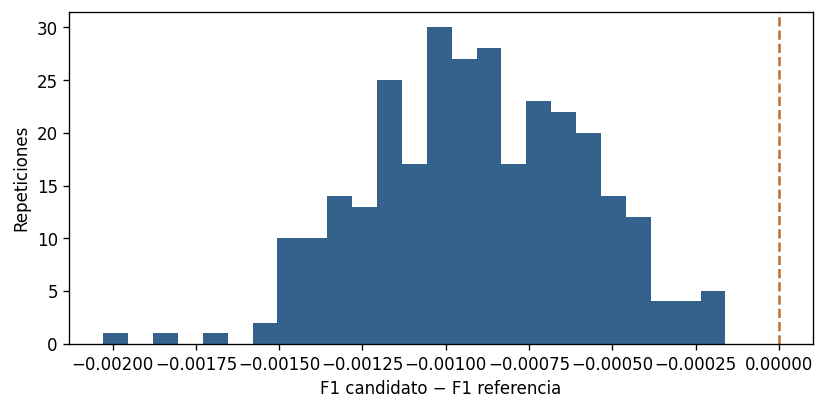

In [ ]:
y=val[TARGET].to_numpy(); a=(pv_nuevo>=t_nuevo); b=(pv_ref>=t_ref)
sem=val.pub_fecha.dt.strftime('%G-%V').to_numpy()
indices=[np.flatnonzero(sem==s) for s in np.unique(sem)]
rng=np.random.default_rng(SEMILLA); diferencias=[]
for _ in range(300):
    ix=np.concatenate([indices[k] for k in rng.integers(len(indices),size=len(indices))])
    diferencias.append(f1_score(y[ix],a[ix],zero_division=0)-f1_score(y[ix],b[ix],zero_division=0))
ic_diferencia=np.quantile(diferencias,[.025,.975])
print('Diferencia puntual:',m_nuevo['f1']-m_ref['f1'])
print('Intervalo orientativo 95% por semanas:',ic_diferencia)
plt.figure(figsize=(7,3.5)); plt.hist(diferencias,bins=25,color='#35628c')
plt.axvline(0,color='#c26c2b',linestyle='--'); plt.xlabel('F1 candidato − F1 referencia'); plt.ylabel('Repeticiones')
plt.tight_layout(); plt.show()

## 8. Modelo de entrega y umbral reciente
Se entrena con enero–octubre, se ajusta el umbral con noviembre–diciembre y se predice 2025 con **ese mismo modelo**. El F1 de noviembre–diciembre de esta celda es un resultado de ajuste, no una evaluación adicional. No se busca forzar un porcentaje determinado de desiertas en test.

In [ ]:
ent_final=datos[datos.pub_fecha<'2024-11-01']
cal_final=datos[datos.pub_fecha>='2024-11-01']
modelos_finales=entrenar_componentes(componentes,ent_final.drop(columns=TARGET),ent_final[TARGET])
p_cal_final=pronosticar(modelos_finales,cal_final.drop(columns=TARGET))
umbral_final=umbral_v2(cal_final[TARGET],p_cal_final,regla_elegida)
p_test=pronosticar(modelos_finales,test)
assert np.isfinite(p_test).all() and ((p_test>=0)&(p_test<=1)).all()
print('Filas de entrenamiento:',len(ent_final),'| Filas para umbral:',len(cal_final))
print('Umbral final:',umbral_final)
display(pd.Series(medir(cal_final[TARGET],p_cal_final,umbral_final),name='Ajuste final, no evaluación'))

por_id=pd.Series((p_test>=umbral_final).astype(int),index=test.id)
submission=plantilla[['id']].copy(); submission[TARGET]=submission.id.map(por_id)
assert submission[TARGET].notna().all()
submission[TARGET]=submission[TARGET].astype(int)
assert submission.id.equals(plantilla.id) and submission.id.is_unique
assert submission.columns.tolist()==plantilla.columns.tolist()
assert len(submission)==21829 and submission[TARGET].isin([0,1]).all()
ARCHIVO='submission_licitaciones_v2.csv'
submission.to_csv(ARCHIVO,index=False)
display(submission.head())
print('Guardado:',ARCHIVO,'| Filas:',len(submission))
print('Porcentaje predicho como desierta:',round(100*submission[TARGET].mean(),2),'%')
pd.DataFrame(filas).to_csv('evaluaciones_v2.csv',index=False)
resumen_v2={'elegido':elegido,'regla':regla_elegida,'componentes':componentes,'umbral':umbral_final,
    'seguimiento_referencia':m_ref,'seguimiento_reentrenado':m_reajuste,'seguimiento_candidato':m_nuevo,
    'ic_diferencia':ic_diferencia.tolist(),'filas_submission':len(submission),
    'proporcion_predicha':float(submission[TARGET].mean()),'sklearn':sklearn.__version__}
Path('configuracion_v2.json').write_text(json.dumps(resumen_v2,indent=2,ensure_ascii=False),encoding='utf-8')

Filas de entrenamiento: 131703 | Filas para umbral: 20850
Umbral final: 0.4067273432811285


f1               0.402695
precision        0.292614
recall           0.645548
ap               0.371680
roc_auc          0.683511
accuracy         0.617266
tasa_predicha    0.440911
Name: Ajuste final, no evaluación, dtype: float64

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,1
4,899379189128,1


Guardado: submission_licitaciones_v2.csv | Filas: 21829
Porcentaje predicho como desierta: 46.09 %


## 9. Conclusión de esta ejecución
Esta conclusión utiliza los valores realmente obtenidos. Un F1 local mayor solo respalda probar el candidato; no permite garantizar superar 0,38168 en Kaggle. Conserva el envío anterior y compara una versión claramente identificada, evitando ajustar repetidamente el umbral a la tabla pública.

**Decisión práctica de esta ejecución:** conservar la referencia anterior. El F1 del candidato bajó ligeramente en noviembre–diciembre y el intervalo por semanas quedó por debajo de cero. La referencia reentrenada obtuvo un F1 local mayor que ambos modelos congelados; por tanto, esta prueba tampoco respalda atribuir al reentrenamiento la caída de Kaggle. El CSV nuevo permite reproducir el experimento, pero no hay evidencia suficiente para recomendarlo como un envío mejor. El puntaje 0,38168 pertenece al envío anterior; todavía no existe un puntaje de Kaggle para este CSV.


**Qué conservar y qué descartar, según la ejecución incluida.** Se conserva la mezcla de 75 % logística y 25 % árboles, con `C=0.2`, `class_weight='balanced'` y el texto con categoría. La logística sin pesos de clase fue la mejor alternativa individual, pero la mezcla de referencia mantuvo el mayor F1 medio con la regla de umbral elegida. Esto no significa que `balanced` sea siempre superior.

Las combinaciones comprador–categoría, los conteos históricos y el aumento de `C` no dieron una mejora suficiente para incorporarlos al modelo de entrega. Sus pruebas quedan documentadas para justificar la decisión. El cambio seleccionado es la regla de umbral; la diferencia en desarrollo es pequeña y debe interpretarse con cautela. El segundo cambio de procedimiento es conservar el modelo después de ajustar su umbral.


In [ ]:
dev_nuevo=tabla_global.loc[(elegido,regla_elegida),'f1_medio']
dev_ref=tabla_global.loc[('Referencia_75_25','maximo'),'f1_medio']
balance='mejoró' if m_nuevo['f1']>m_ref['f1'] else 'no mejoró'
evidencia='incluye cero: no demuestra una ventaja clara' if ic_diferencia[0]<=0<=ic_diferencia[1] else 'no incluye cero en este remuestreo'
display(Markdown(f"""**Selección:** `{elegido}`, umbral `{regla_elegida}`.

En desarrollo: F1 medio **{dev_nuevo:.4f}**, frente a **{dev_ref:.4f}** de la referencia.

En seguimiento: el candidato **{balance}** frente a la referencia congelada: **{m_nuevo['f1']:.4f}** frente a **{m_ref['f1']:.4f}**. La referencia reentrenada obtuvo **{m_reajuste['f1']:.4f}**; esa diferencia permite comprobar el efecto del reentrenamiento en este período, sin atribuirle automáticamente el cambio de Kaggle.

El intervalo de diferencia por semanas es **[{ic_diferencia[0]:.4f}, {ic_diferencia[1]:.4f}]** y **{evidencia}**.

El candidato detecta el **{100*m_nuevo['recall']:.1f} %** de las desiertas reales; el **{100*m_nuevo['precision']:.1f} %** de sus alertas son correctas. F1 no es el porcentaje total de aciertos.

Para el CSV se entrenó hasta octubre y se fijó el umbral **{umbral_final:.4f}** con noviembre–diciembre. Luego se conservaron modelo y umbral para predecir test. La señal de mejora debe confirmarse en datos nuevos: los períodos de 2024 ya participaron en el proyecto y no constituyen una prueba nueva intocada.
"""))

**Selección:** `Referencia_75_25`, umbral `estable`.

En desarrollo: F1 medio **0.3901**, frente a **0.3894** de la referencia.

En seguimiento: el candidato **no mejoró** frente a la referencia congelada: **0.3964** frente a **0.3973**. La referencia reentrenada obtuvo **0.4024**; esa diferencia permite comprobar el efecto del reentrenamiento en este período, sin atribuirle automáticamente el cambio de Kaggle.

El intervalo de diferencia por semanas es **[-0.0015, -0.0003]** y **no incluye cero en este remuestreo**.

El candidato detecta el **63.2 %** de las desiertas reales; el **28.9 %** de sus alertas son correctas. F1 no es el porcentaje total de aciertos.

Para el CSV se entrenó hasta octubre y se fijó el umbral **0.4067** con noviembre–diciembre. Luego se conservaron modelo y umbral para predecir test. La señal de mejora debe confirmarse en datos nuevos: los períodos de 2024 ya participaron en el proyecto y no constituyen una prueba nueva intocada.


In [ ]:
# Descarga del archivo en Colab.
try:
    from google.colab import files
except ImportError:
    print('El CSV está guardado en la carpeta de trabajo.')
else:
    files.download(ARCHIVO)

El CSV está guardado en la carpeta de trabajo.


## Referencias y límites
Datos: los tres CSV proporcionados por el usuario. El score 0,38168 se registra como referencia de la captura, no se usa como etiqueta ni objetivo de ajuste. No se incorporan datos externos.

- [Selección del umbral — documentación de scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [Validación y riesgo de reutilizar conjuntos de evaluación](https://scikit-learn.org/stable/modules/cross_validation.html)

No se conoce la disponibilidad exacta de cada desenlace ni si los campos de publicación fueron revisados después. Los modelos se basan en la información entregada y su utilidad real debe comprobarse fuera de 2024. Guarda el notebook ejecutado y sus resultados para presentar el razonamiento, incluidos los cambios que no mejoraron.